# Evaluate the model

Use the JuniperMapper fieldwork data to validate the trained model. To evaluate the overall model performance, three metrics were used:

1. Precision metric: assess how precise the model is in delineating the shrubs
2. Recall: evaluate how accurate the model is in recalling the shrubs
3. F1-score: examine the ability of the model to maintain the trade-off precision–recall.

$$
Precision = \frac{TP}{TP+FP}
$$

$$
Recall = \frac{TP}{TP+FN}
$$

$$
F1 = \frac{2PR}{P+R}
$$

For Mask R-CNN, there are two useful interpretations of Precision, Recall, and F1:

1. Pixel-level segmentation metrics: measure how precisely the predicted masks delineate shrub pixels.
2. Instance-level detection metrics: measure whether individual shrubs are found, using a mask-IoU threshold.

This code reporting both, although the reference paper ([Khaldi et al. 2024](https://doi.org/10.1016/j.jag.2024.104191)) report only instance-level detection.

Mask R-CNN repository returns instance masks in `r["masks"]`, class IDs in `r["class_ids"]`, confidence scores in `r["scores"]`, and boxes in `r["rois"]`.

In [1]:
import os
import sys

import matplotlib.pyplot as plt

sys.path.append(os.path.join(os.path.dirname(os.getcwd()), 'bin'))
import mrcnn.model as modellib
from mrcnn import utils
from shrubs import ShrubDataset
from shrubs import ShrubValConfig
from shrubs import evaluate_pixel_metrics
from shrubs import evaluate_instance_metrics
from shrubs import evaluate_instance_metrics_s_iou
from shrubs import compute_iou_range
from shrubs import compute_siou_range
from shrubs import plot_performance

Using TensorFlow backend.


## Configurations

In [2]:
%matplotlib inline 

ROOT = os.path.join(os.path.dirname(os.getcwd()))

# Directory to save logs and trained model
MODEL_DIR = os.path.join(ROOT, "data/logs")

# Directory with Val data
VAL_DIR_PI = os.path.join(
    ROOT,
    "data/JuniperMapper", "Photo_Interpretation_Data/Val"
)

VAL_DIR_FW = os.path.join(
    ROOT,
    "data/JuniperMapper", "Field_Work_Data/External_Val_Data"
)

In [3]:
# Validation datasets
dataset_val_pi = ShrubDataset()
dataset_val_pi.load_dataset(
    os.path.join(VAL_DIR_PI, "Images"),
    os.path.join(VAL_DIR_PI, "masks_points.json")
)
dataset_val_pi.prepare()

In [4]:
config = ShrubValConfig()

# Create model in testing mode
model = modellib.MaskRCNN(
    mode="inference",
    config=config,
    model_dir=MODEL_DIR
)

# Get path to saved weights
# Either set a specific path or find last trained weights
# model_path = os.path.join(ROOT_DIR, ".h5 file name here")
model_path = model.find_last()

# Load trained weights
print("Loading weights from ", model_path)
model.load_weights(model_path, by_name=True)

Loading weights from  c:\IRANZO\shrubs-segmentation\data/logs\shrubs_cfg\mask_rcnn_shrubs_cfg_0020.h5


## Pixel-level metrics

Combine all shrub-instance masks in an image into one binary shrub mask. Then count the three metrics to assess overall model performance. `TP`, `FP`, and `FN` are numbers of pixels.

In [5]:
pixel_results, pixel_results_per_image = evaluate_pixel_metrics(
    model=model,
    dataset_test=dataset_val_pi,
    shrub_class_id=1,
    confidence_threshold=0.5
)

print("Pixel-level evaluation for PI validation set")
print(f"Precision: {pixel_results['precision']:.4f}")
print(f"Recall:    {pixel_results['recall']:.4f}")
print(f"F1-score:  {pixel_results['f1']:.4f}")
print(f"TP pixels: {pixel_results['tp_pixels']}")
print(f"FP pixels: {pixel_results['fp_pixels']}")
print(f"FN pixels: {pixel_results['fn_pixels']}")


Pixel-level evaluation for PI validation set
Precision: 0.7799
Recall:    0.8102
F1-score:  0.7948
TP pixels: 602858
FP pixels: 170097
FN pixels: 141236


These metrics answer:

* **Pixel Precision:** Of all pixels labelled as shrubs, how many really belong to shrubs?
* **Pixel Recall:** Of all annotated shrub pixels, how many were recovered?
* **Pixel F1:** How well does the model balance over-segmentation and under-segmentation?

## Instance-level metrics

For instance-level evaluation, a predicted shrub is a true positive when:

* its class is shrub
* it has not already been matched to another ground-truth shrub
* its mask IoU with a ground-truth shrub is at least the selected threshold

The function `mrcnn.utils.compute_matches()` calculates mask overlaps and performs one-to-one matching between predictions and ground-truth instances. It uses mask IoU rather than bounding-box IoU, so this evaluation considers the quality of the predicted segmentation when deciding whether a shrub was detected correctly.

In [ ]:
instance_results, instance_results_per_image = evaluate_instance_metrics(
    model=model,
    dataset_test=dataset_val_pi,
    shrub_class_id=1,
    confidence_threshold=0.9,
    iou_threshold=0.5
)

print("Instance-level evaluation using IoU")
print(f"Precision: {instance_results['precision']:.4f}")
print(f"Recall:    {instance_results['recall']:.4f}")
print(f"F1-score:  {instance_results['f1']:.4f}")
print(f"TP shrubs: {instance_results['true_positive_predictions']}")
print(f"FP shrubs: {instance_results['false_positive_predictions']}")
print(f"FN shrubs: {instance_results['false_negative_ground_truths']}")

Instance-level evaluation
Precision: 0.6782
Recall:    0.7121
F1-score:  0.6948
TP shrubs: 470
FP shrubs: 223
FN shrubs: 190


The paper where JuniperMapper dataset is evaluated ([Khaldi et al. 2024](https://doi.org/10.1016/j.jag.2024.104191)) used also a S-IoU metric to assess the instance-level metrics. The S-IoU

> evaluates the proportion of shrubs' areas being detected by the model since they divide the intersection by the ground truth area and they use all matching ground truth shrubs instead fo the best matching shrub. This metric evaluates the predictions and labels differently. The first equation was used to identify the number of TPs and FPs, while the second was used to identify the number of FNs.

$$
\mathrm{S\text{-}IoU}(p, S_{l_{\mathrm{match}}})
=
\frac{
\operatorname{Area}\left(
p \cap \bigcup_{k=1}^{\left|S_{l_{\mathrm{match}}}\right|} l_k
\right)
}{
\operatorname{Area}\left(
\bigcup_{k=1}^{\left|S_{l_{\mathrm{match}}}\right|} l_k
\right)
}
$$

$$
\mathrm{S\text{-}IoU}(l, S_{p_{\mathrm{match}}})
=
\frac{
\operatorname{Area}\left(
l \cap \bigcup_{k=1}^{\left|S_{p_{\mathrm{match}}}\right|} p_k
\right)
}{
\operatorname{Area}(l)
}
$$

where: $S_{p_{\mathrm{match}}}$ the set of all matching predictions. $S_{l_{\mathrm{match}}}$ is the set of all matching labels. $l_k$ and $p_k$ are the label and prediction of id $k$, respectively.

We defined a new function to address this new metric, computing the two independent calculations required by S-IoU metric:

- Prediction -> labels: determines whether each prediction is TP or FP.
- Label -> predictions: determines whether each ground-truth instance is detected or is an FN.

The custom function `compute_s_iou_matches` is able to match one label to several predictions and several labels to one prediction. The new implementation defines matching instances as same-class masks with positive overlap.

> Note: The [Khaldi et al. 2024](https://doi.org/10.1016/j.jag.2024.104191) paper uses the prediction-directed TP count in both precision and recall, even though FN is obtained independently through label-directed evaluation.

Paper-compatible interpretation:

```txt
Matching set:
    All same-class masks with at least one intersecting pixel.

S-IoU threshold:
    Applied after unioning matching masks.

Prediction evaluation:
    S-IoU(p, matching labels) >= threshold -> TP
    Otherwise -> FP

Label evaluation:
    S-IoU(l, matching predictions) < threshold -> FN

Precision:
    TP / (TP + FP)

Recall:
    TP / (TP + FN)
```

In [7]:
instance_results = evaluate_instance_metrics_s_iou(
    model=model,
    dataset_test=dataset_val_pi,
    shrub_class_id=1,
    confidence_threshold=0.9,
    siou_threshold=0.5
)

print("Instance-level evaluation using S-IoU")
print(f"Precision: {instance_results['precision']:.4f}")
print(f"Recall:    {instance_results['recall']:.4f}")
print(f"F1-score:  {instance_results['f1']:.4f}")
print(f"TP shrubs: {instance_results['true_positive_predictions']}")
print(f"FP shrubs: {instance_results['false_positive_predictions']}")
print(f"FN shrubs: {instance_results['false_negative_ground_truths']}")

Instance-level evaluation using S-IoU
Precision: 0.8074
Recall:    0.6587
F1-score:  0.7255
TP shrubs: 415
FP shrubs: 99
FN shrubs: 215


### Iterate between several confident thresholds

Use a declared pair of thresholds.

* The **confidence threshold** controls which predicted instances are included.
* The **mask-IoU threshold** controls how closely a predicted mask must overlap an annotation to count as a correct shrub instance.

Evaluate reports results at several IoU thresholds and save them to a csv file.


In [6]:
iou_threshold = 0.75

out_csv_file = f"iou_threshold_{iou_threshold}_metrics.csv"

compute_iou_range(model, dataset_val_pi, out_csv_file, iou_threshold)

IoU=0.75: Confidence score threshold=0.0 P=0.5152, R=0.5409, F1=0.5277
IoU=0.75: Confidence score threshold=0.05 P=0.5152, R=0.5409, F1=0.5277
IoU=0.75: Confidence score threshold=0.1 P=0.5152, R=0.5409, F1=0.5277
IoU=0.75: Confidence score threshold=0.15 P=0.5152, R=0.5409, F1=0.5277
IoU=0.75: Confidence score threshold=0.2 P=0.5152, R=0.5409, F1=0.5277
IoU=0.75: Confidence score threshold=0.25 P=0.5152, R=0.5409, F1=0.5277
IoU=0.75: Confidence score threshold=0.3 P=0.5152, R=0.5409, F1=0.5277
IoU=0.75: Confidence score threshold=0.35 P=0.5152, R=0.5409, F1=0.5277
IoU=0.75: Confidence score threshold=0.4 P=0.5152, R=0.5409, F1=0.5277
IoU=0.75: Confidence score threshold=0.45 P=0.5152, R=0.5409, F1=0.5277
IoU=0.75: Confidence score threshold=0.5 P=0.5152, R=0.5409, F1=0.5277
IoU=0.75: Confidence score threshold=0.55 P=0.5152, R=0.5409, F1=0.5277
IoU=0.75: Confidence score threshold=0.6 P=0.5152, R=0.5409, F1=0.5277
IoU=0.75: Confidence score threshold=0.65 P=0.5152, R=0.5409, F1=0.5277

Higher IoU thresholds impose stricter delineation requirements. The `mrcnn` repository also provides `compute_ap()` and `compute_ap_range()` for precision–recall curves and AP evaluation at one or several IoU thresholds.


In [6]:
siou_threshold = 0.5

out_csv_file = f"siou_threshold_{siou_threshold}_metrics.csv"

compute_siou_range(model, dataset_val_pi, out_csv_file, siou_threshold)

S-IoU=0.50: Confidence score threshold=0.0 P=0.6739, R=0.7436, F1=0.7070
S-IoU=0.50: Confidence score threshold=0.05 P=0.6739, R=0.7436, F1=0.7070
S-IoU=0.50: Confidence score threshold=0.1 P=0.6739, R=0.7436, F1=0.7070
S-IoU=0.50: Confidence score threshold=0.15 P=0.6739, R=0.7436, F1=0.7070
S-IoU=0.50: Confidence score threshold=0.2 P=0.6739, R=0.7436, F1=0.7070
S-IoU=0.50: Confidence score threshold=0.25 P=0.6739, R=0.7436, F1=0.7070
S-IoU=0.50: Confidence score threshold=0.3 P=0.6739, R=0.7436, F1=0.7070
S-IoU=0.50: Confidence score threshold=0.35 P=0.6739, R=0.7436, F1=0.7070
S-IoU=0.50: Confidence score threshold=0.4 P=0.6739, R=0.7436, F1=0.7070
S-IoU=0.50: Confidence score threshold=0.45 P=0.6739, R=0.7436, F1=0.7070
S-IoU=0.50: Confidence score threshold=0.5 P=0.6739, R=0.7436, F1=0.7070
S-IoU=0.50: Confidence score threshold=0.55 P=0.6739, R=0.7436, F1=0.7070
S-IoU=0.50: Confidence score threshold=0.6 P=0.6739, R=0.7436, F1=0.7070
S-IoU=0.50: Confidence score threshold=0.65 P

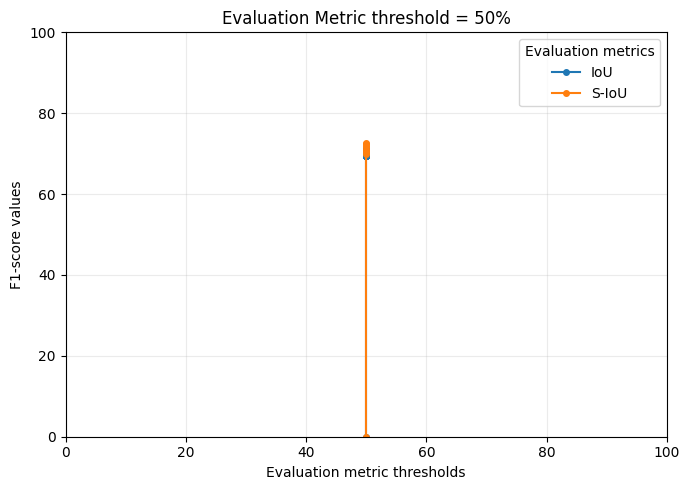

Figure saved to: evaluation_metrics_confidence_50.png


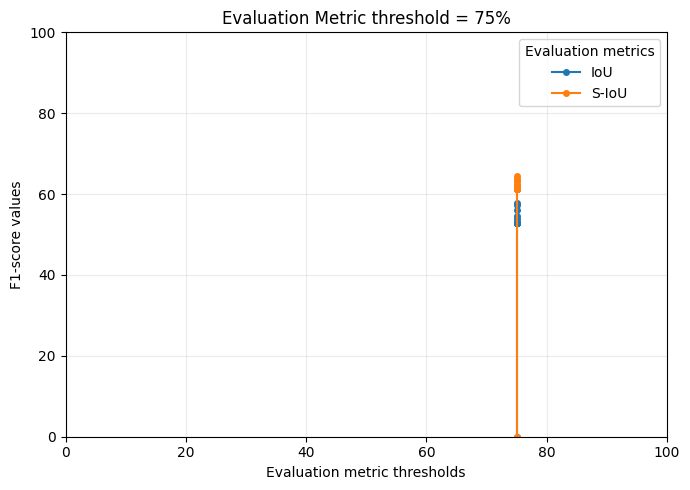

Figure saved to: evaluation_metrics_confidence_75.png


In [2]:
csv_files = {
    0.50: {
        "IoU": "iou_threshold_0.5_metrics.csv",
        "S-IoU": "siou_threshold_0.5_metrics.csv",
    },
    0.75: {
        "IoU": "iou_threshold_0.75_metrics.csv",
        "S-IoU": "siou_threshold_0.75_metrics.csv",
    },
}

plot_performance(csv_files)